In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/sample_submission.csv
/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/train.csv
/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/metadata.csv
/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/test.csv


# Imports

In [2]:
# Data manipulation and mathematical operations
import pandas as pd 
import numpy as np 

# Data visualization and plotting libraries
import matplotlib.pyplot as plt 
import seaborn as sns 

# Scikit-learn base classes for custom estimators and cloning
from sklearn.base import BaseEstimator, TransformerMixin, RegressorMixin, clone 

# Data preprocessing, imputation, and pipeline orchestration
from sklearn.compose import ColumnTransformer, make_column_selector as selector
from sklearn.impute import SimpleImputer 
from sklearn.pipeline import Pipeline 

# Machine learning regression models
from sklearn.linear_model import LinearRegression 
import lightgbm as lgb 
import xgboost as xgb 
from catboost import CatBoostRegressor 

# Model validation, hyperparameter tuning, and performance metrics
from sklearn.model_selection import GroupKFold, RandomizedSearchCV 
from sklearn.metrics import mean_squared_error as mse 

# System memory management and garbage collection
import gc 


# Load data

In [3]:
train_df = pd.read_csv("/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/train.csv", low_memory = False)
test_df = pd.read_csv("/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/test.csv", low_memory = False)
sample_sub = pd.read_csv("/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/sample_submission.csv", low_memory = False)
metadata = pd.read_csv("/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/metadata.csv", low_memory = False)

# Understanding the problem

We have been given a dataset that provides comprehensive operational, transactional, and technical insights into how a global platform tracks, structures, and processes heavy industrial machinery and equipment lifecycles. Each record in the dataset captures a single, finalized accounting or operational event, complete with system metadata, geographic indicators, deep component specifications, and mechanical configurations.

Out goal is to explore this dataset and predict the selling price of the heavy machinery

Problem type: Regression  
Evaluation metric: RMSLE Score

# Understanding the dataset

In [4]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)
metadata

,Variable,Rephrased Description
0,TransactionID,A unique serial number assigned to each individual accounting record.
1,TargetValue,"The financial amount of the transaction, denominated in US Dollars."
2,AssetID,The internal tracking number assigned to a specific piece of hardware.
3,ProductConfigID,A system-generated code representing the technical build-out of the unit.
4,DataOriginCode,A code indicating the specific software or platform where the data originated.
5,VendorPartnerID,The unique ID of the external entity or third-party provider involved.
6,TransactionDate,The official calendar date when the entry was finalized in the system.
7,RegionCode,The specific geographic area or legal jurisdiction where the event occurred.
8,ManufactureYear,The year the asset was originally produced.
9,OperationalHoursMeter,The lifetime total of active run-time or work cycles logged by the machine.


## Observations

- TransactionID is the identifying column of each record
- The target value is "TargetValue", the selling price of the machine
- AssetID is like a serial number assigned to each machine

**Important observation**: 

If the same AssetID appears multiple times in the dataset, then we will use **GroupKFold** so that there is no data leakage. The model should not use AssetID to predict the price. If it does so, it will not be able to generalise properly to unknown machines


In [5]:
train_df['AssetID'].value_counts()

AssetID
2283600    46
1896862    36
2285838    35
1746400    30
1942732    29
           ..
1259934     1
1150826     1
1535549     1
1541413     1
1231846     1
Name: count, Length: 120111, dtype: int64

In [6]:
target = "TargetValue"

# EDA and Data Cleaning

## Dataset overview

### Shape

Number of rows and features in the dataset

In [7]:
train_df.shape

(138701, 50)

This dataset has 138701 rows and 50 columns(features), including target variable

### Head

In [8]:
train_df.head()

,TransactionID,TargetValue,AssetID,ProductConfigID,DataOriginCode,VendorPartnerID,ManufactureYear,OperationalHoursMeter,UtilizationTier,TransactionDate,Spec_FullDescriptor,Spec_BaseClass,Spec_SubClass,Spec_ReleaseSeries,Spec_VariantModifier,AssetScaleFactor,FunctionalClassification,RegionCode,InventoryGroupCategory,InventoryGroupDescription,col1,CabinType,Forks,col3,col4,DrivetrainType,col5,col6,col7,col8,col9,col10,col11,col12,col13,col14,col15,col16,col18,col19,col20,col21,col22,col23,col24,col25,col27,col28,col29,col30
0,1139309,57000.0,117665,88,ACH138,GTX,1997,4640.0,Low,2005-03-26,950FII,950,F,II,NaN,Medium,Wheel Loader - 150.0 to 175.0 Horsepower,North Carolina,WL,Wheel Loader,NaN,EROPS w AC,None or Unspecified,None or Unspecified,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2 Valve,NaN,NaN,NaN,NaN,23.5,None or Unspecified,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Standard,Conventional
1,1139316,26500.0,1001282,4616,ACH138,GTX,2005,508.0,Low,2009-12-18,310G,310,G,NaN,NaN,NaN,Backhoe Loader - 14.0 to 15.0 Ft Standard Digging Depth,Arizona,BL,Backhoe Loaders,Four Wheel Drive,OROPS,None or Unspecified,No,Extended,Powershuttle,None or Unspecified,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1139317,21000.0,772709,1948,ACH138,GTX,1994,11540.0,High,2005-08-26,790ELC,790,E,NaN,LC,Large / Medium,"Hydraulic Excavator, Track - 21.0 to 24.0 Metric Tons",Florida,TEX,Track Excavators,NaN,EROPS,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Standard,NaN,NaN,NaN,NaN,NaN,None or Unspecified,NaN,NaN,Steel,None or Unspecified,None or Unspecified,None or Unspecified,None or Unspecified,Double,NaN,NaN,NaN,NaN
3,1139322,27000.0,902010,3550,ACH138,GTX,2002,4883.0,High,2006-11-17,416D,416,D,NaN,NaN,NaN,Backhoe Loader - 14.0 to 15.0 Ft Standard Digging Depth,Illinois,BL,Backhoe Loaders,Four Wheel Drive,OROPS,None or Unspecified,No,Standard,Standard,Yes,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1139333,21500.0,1036259,36014,ACH138,GTX,2009,302.0,Low,2010-08-27,430HAG,430,HAG,NaN,NaN,Mini,"Hydraulic Excavator, Track - 3.0 to 4.0 Metric Tons",Texas,TEX,Track Excavators,NaN,EROPS,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Auxiliary,NaN,NaN,NaN,NaN,NaN,Manual,NaN,NaN,Rubber,None or Unspecified,None or Unspecified,None or Unspecified,None or Unspecified,Double,NaN,NaN,NaN,NaN


**Note:** Some values are "None or unspecified". They have to be converted into NaN

### Datatypes

In [9]:
train_df.dtypes

TransactionID                  int64
TargetValue                  float64
AssetID                        int64
ProductConfigID                int64
DataOriginCode                object
VendorPartnerID               object
ManufactureYear                int64
OperationalHoursMeter        float64
UtilizationTier               object
TransactionDate               object
Spec_FullDescriptor           object
Spec_BaseClass                object
Spec_SubClass                 object
Spec_ReleaseSeries            object
Spec_VariantModifier          object
AssetScaleFactor              object
FunctionalClassification      object
RegionCode                    object
InventoryGroupCategory        object
InventoryGroupDescription     object
col1                          object
CabinType                     object
Forks                         object
col3                          object
col4                          object
DrivetrainType                object
col5                          object
c

In [10]:
train_df.dtypes.value_counts()

object     44
int64       4
float64     2
Name: count, dtype: int64

Very huge number of columns are of object datatype. Only 6 (4 int +2 float) columns are numeric

## Target variable analysis

In [11]:
train_df[target].describe()

count    138701.000000
mean      41521.874047
std       26361.125948
min        7500.000000
25%       20500.000000
50%       35000.000000
75%       57000.000000
max      142000.000000
Name: TargetValue, dtype: float64

Skewness: 0.97


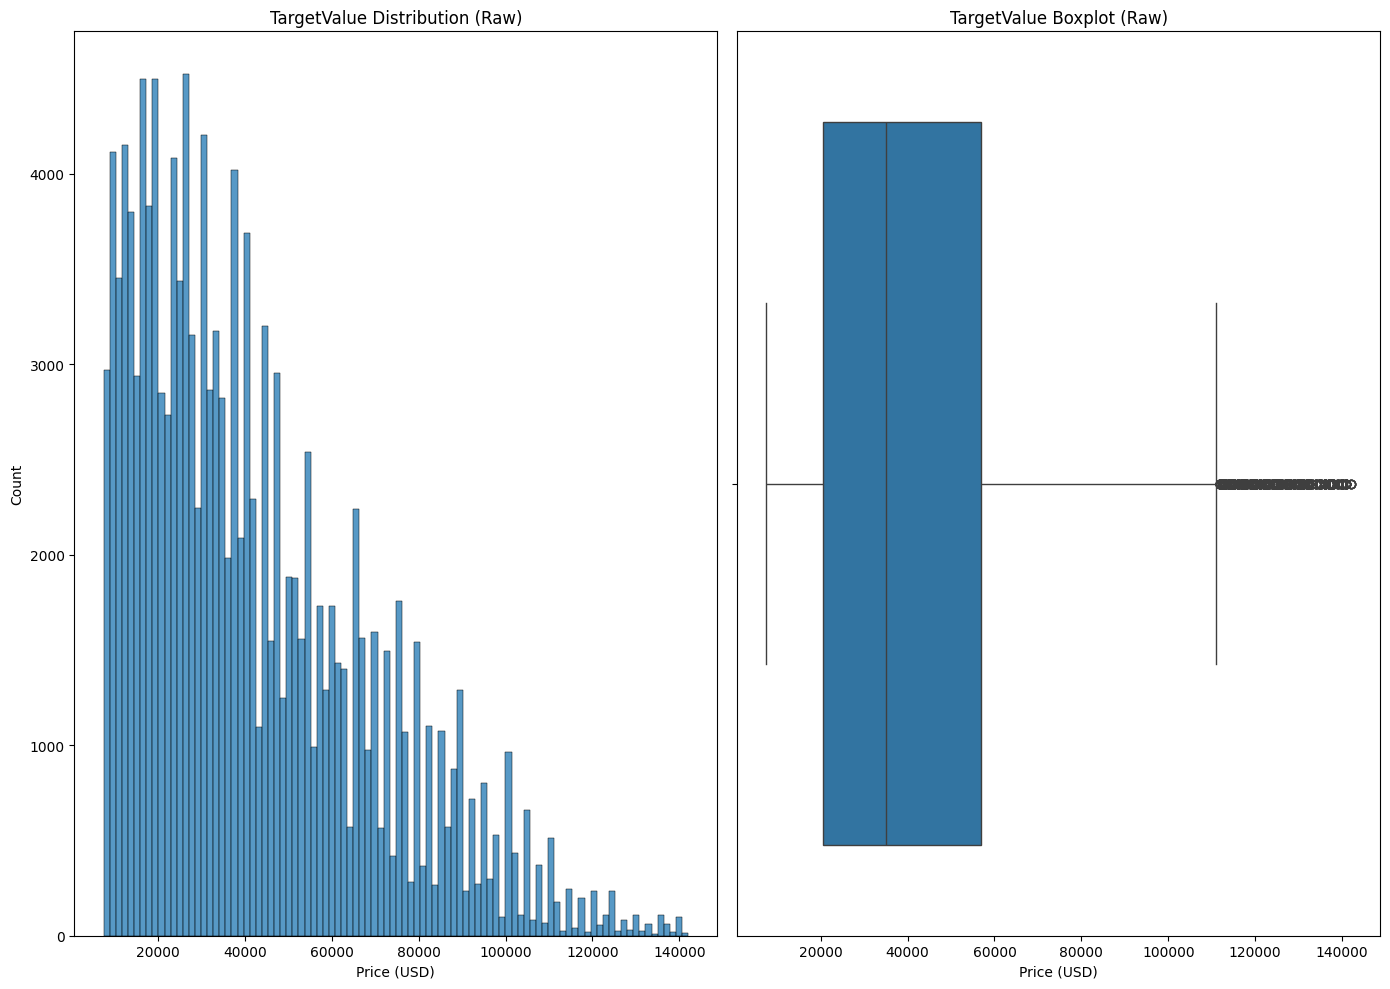

In [12]:
print(f"Skewness: {train_df['TargetValue'].skew():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 10))

# Raw distribution
sns.histplot(train_df['TargetValue'], ax=axes[0])
axes[0].set_title('TargetValue Distribution (Raw)')
axes[0].set_xlabel('Price (USD)')

# Raw boxplot
sns.boxplot(x=train_df['TargetValue'], ax=axes[1])
axes[1].set_title('TargetValue Boxplot (Raw)')
axes[1].set_xlabel('Price (USD)')


plt.tight_layout()
plt.show()

We can see that the target variable is right-skewed. Hence, we shall check if a log transform handles the skewness effectively

Skewness after log: -0.20


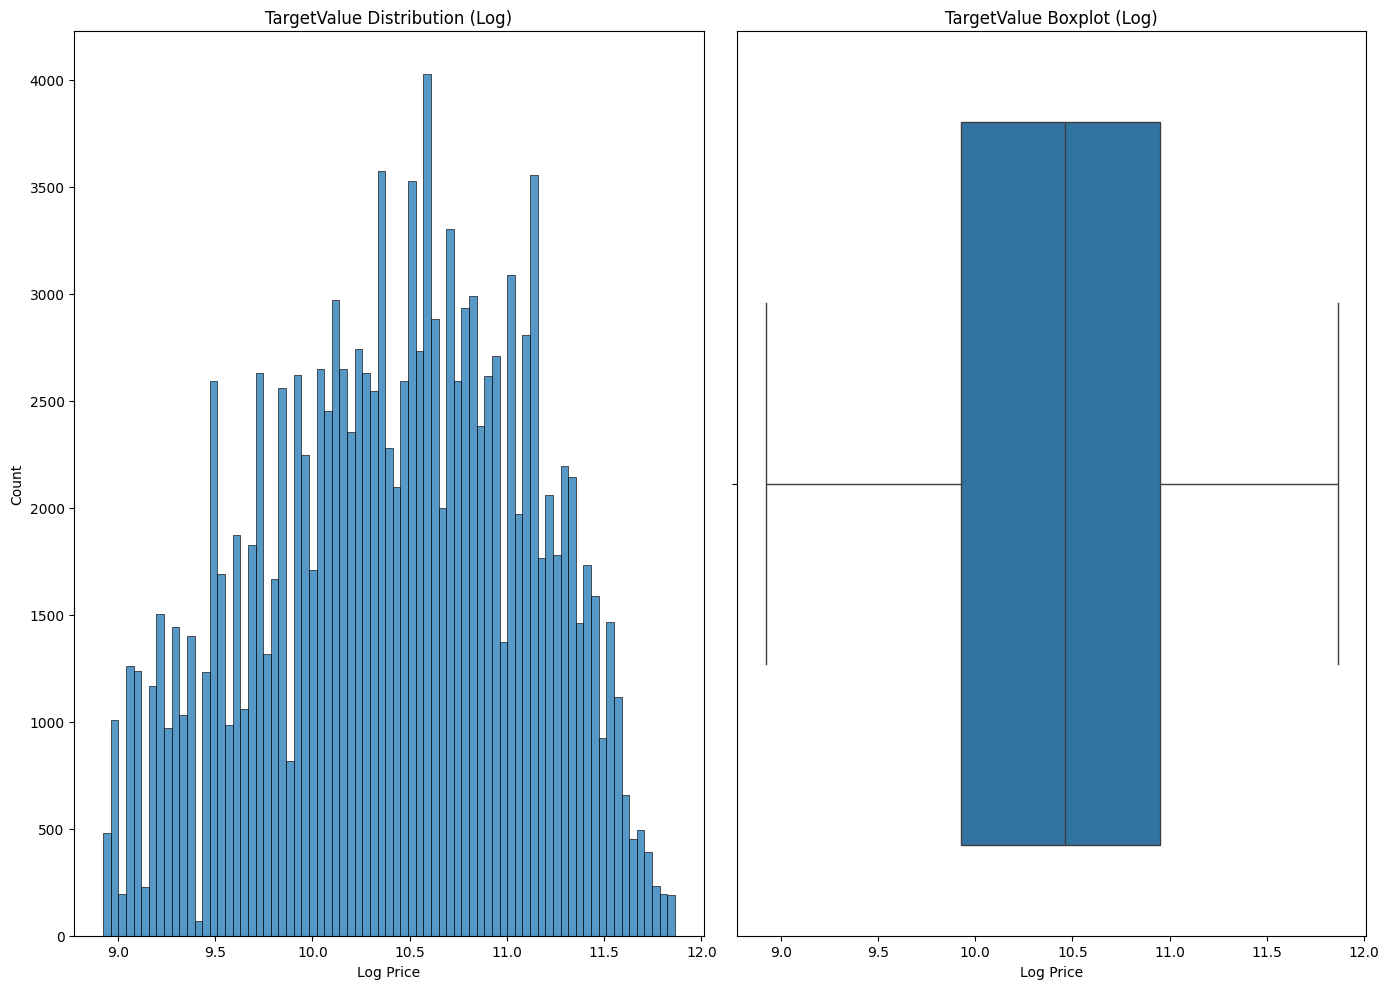

In [13]:
print(f"Skewness after log: {np.log1p(train_df['TargetValue']).skew():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 10))

# Log distribution
sns.histplot(np.log1p(train_df['TargetValue']), ax=axes[0])
axes[0].set_title('TargetValue Distribution (Log)')
axes[0].set_xlabel('Log Price')

# Log boxplot
sns.boxplot(x=np.log1p(train_df['TargetValue']), ax=axes[1])
axes[1].set_title('TargetValue Boxplot (Log)')
axes[1].set_xlabel('Log Price')

plt.tight_layout()
plt.show()

The skewness is handled really well by the log transform. Hence, no outlier treatment required for target value

## Check duplicates

In [14]:
train_df['TransactionID'].duplicated().sum()

np.int64(0)

Yay! There are no duplicated rows in the dataset!

## Null analysis

### Replace other versions of null with NaN

During dataset overview, we came across "None or Unspecified" values which have to be converted into NaN

In [15]:
train_df.replace("None or Unspecified", np.nan, inplace=True)
test_df.replace("None or Unspecified", np.nan, inplace=True)

Let's check if there are any more values like that, which might actually mean NaN

In [16]:
for col in train_df.select_dtypes(include='object').columns:
    suspicious = train_df[col][train_df[col].str.strip().str.lower().isin([
        'none', 'null', 'na', 'n/a', 'nan', 'not specified', 
        'none or unspecified', 'unknown', 'unspecified', '-', '', ' '
    ])].unique()
    if len(suspicious) > 0:
        print(f"{col}: {suspicious}")

RegionCode: ['Unspecified']


We have caught an "Unspecified" which is actually just NaN! Let's replace it!

In [17]:
train_df.replace("Unspecified", np.nan, inplace=True)
test_df.replace("Unspecified", np.nan, inplace=True)

### Null percentages

In [18]:
features_with_na = []
for col in train_df.columns:
    null_percent = train_df[col].isnull().mean()*100
    if null_percent!=0.0:
        features_with_na.append(col)
        print(f"{col:<35} null%: {null_percent}%")
    

OperationalHoursMeter               null%: 40.838205924975306%
UtilizationTier                     null%: 63.608769943980214%
Spec_SubClass                       null%: 26.665272781018164%
Spec_ReleaseSeries                  null%: 76.28279536557055%
Spec_VariantModifier                null%: 62.269918746079696%
AssetScaleFactor                    null%: 29.71139357322586%
RegionCode                          null%: 0.422491546564192%
col1                                null%: 75.64112731703449%
Forks                               null%: 96.77003049725668%
col3                                null%: 89.668423443234%
col4                                null%: 92.51555504286199%
DrivetrainType                      null%: 80.34404943006899%
col5                                null%: 99.66114159234613%
col6                                null%: 99.62941867758704%
col7                                null%: 89.30937772618799%
col8                                null%: 97.71018233466233%
col9  

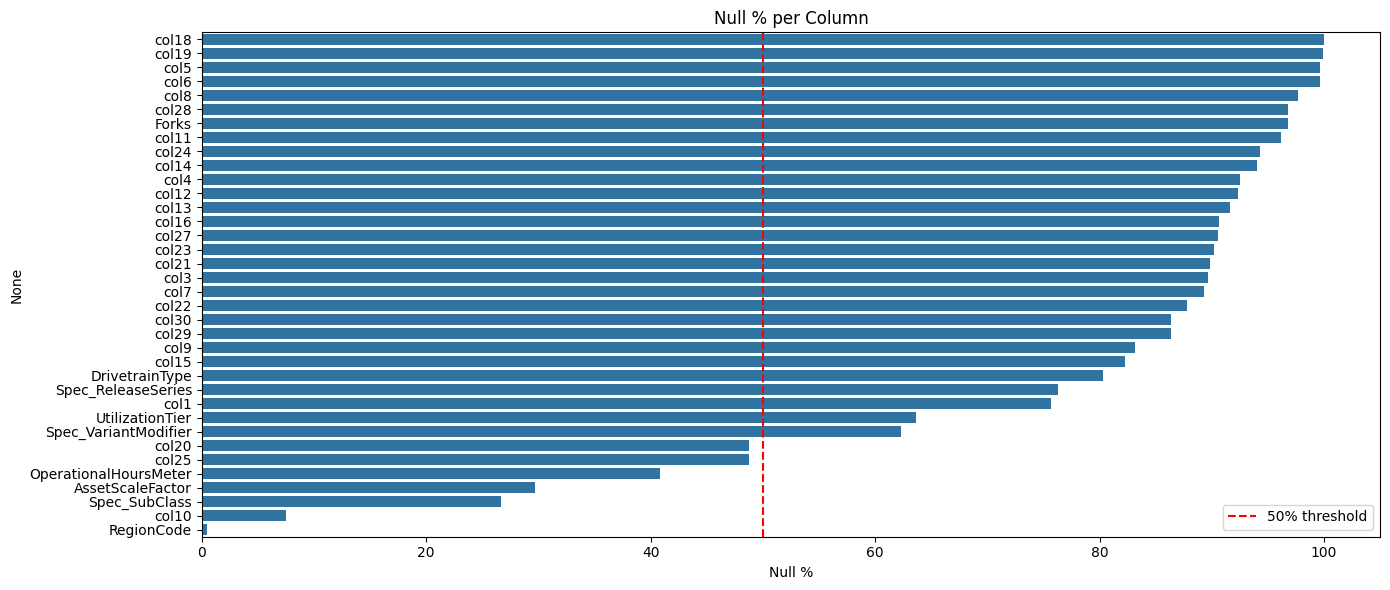

In [19]:
#Null values bar graph
null_pct = train_df[features_with_na].isnull().mean() * 100
null_pct = null_pct.sort_values(ascending=False)

plt.figure(figsize=(14, 6))
sns.barplot(x=null_pct.values, y=null_pct.index)
plt.title('Null % per Column')
plt.xlabel('Null %')
plt.axvline(x=50, color='red', linestyle='--', label='50% threshold')
plt.legend()
plt.tight_layout()
plt.show()

**Note:** The high amount of nulls makes it difficult to drop or impute. Hence, we can prefer models that native handle null values. For example, tree-based models like Random Forests, LightGBM, XGBoost, etc

* A straightforward approach would be to drop the columns with high null values (As suggested in the milestone assignment)
* However, some high null columns might actually be structural! This means, maybe not all types of machines have that value, and for those that do have that value, it might be significant!
* We can check this by seeing if the value of that column is 100% null in one type of machine while having less or even 0% nulls in other types of machines

### Check for structural nulls

Some columns with high nulls might just be applicable for only few types of machines

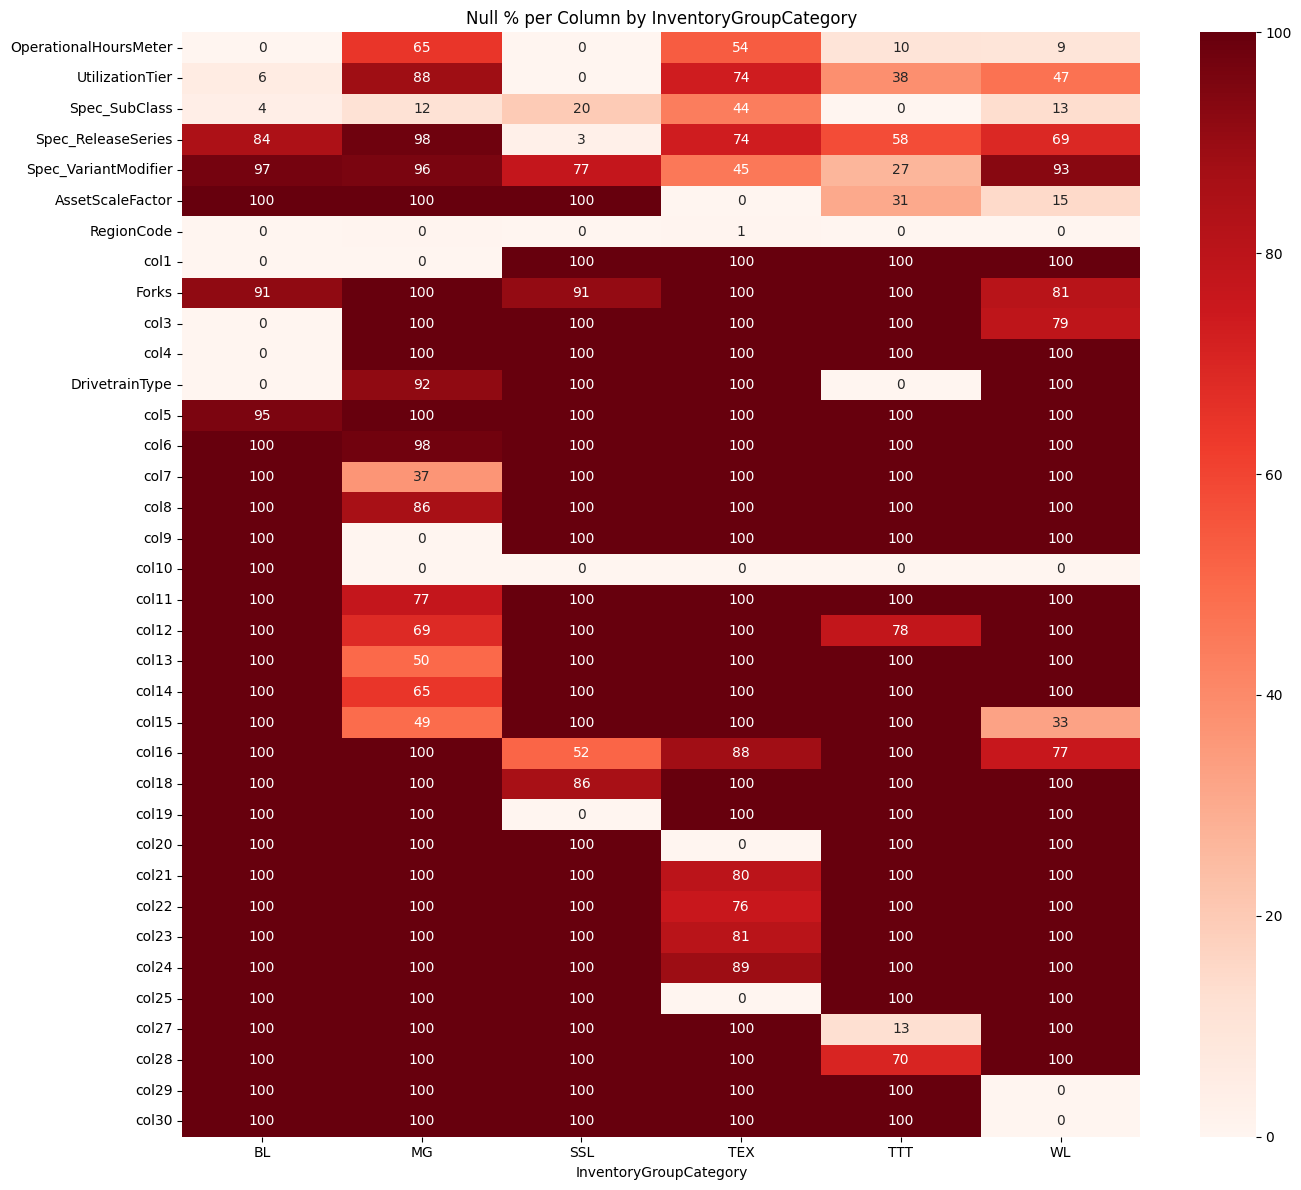

In [20]:
#Heatmap with InventoryGroupCategory

null_by_cat = train_df.groupby('InventoryGroupCategory')[features_with_na].apply(
    lambda x: x.isnull().mean() * 100
).T

plt.figure(figsize=(14, 12))
sns.heatmap(null_by_cat, annot=True, fmt='.0f', cmap='Reds')
plt.title('Null % per Column by InventoryGroupCategory')
plt.tight_layout()
plt.show()

### We can see that most of these nulls are structural nulls!

### Observations:

**Columns with high nulls across all categories, which can be dropped**:
* Forks
* col5
* col6
* col8
* col18
* col23
* col24

In [21]:
cols_to_drop = ['Forks', 'col5', 'col6', 'col8', 'col18', 'col23', 'col24']

**Columns which have structural nulls**:
* AssetScaleFactor
* col1
* col3
* col4
* DrivetrainType
* col7
* col9
* col10
* col11
* col12
* col13
* col14
* col15
* col16
* col19
* col20
* col21
* col22
* col25
* col27
* col28
* col29
* col30

**Columns with non-structural nulls**:
* OperationalHoursMeter
* UtilizationTier
* Spec_Subclass
* Spec_ReleaseSeries
* Spec_VariantModifier
* RegionCode

Here, only RegionCode has minimal percentage of nulls, which can be imputed using mode. Other columns have high nulls, and imputing can cause noise. Hence, we can use tree-based models, and let the model natively handle those nulls

## Datatype conversions

The first obvious conversion in TransactionDate, which is converted into datetime so that meaningful features can be extracted from it

In [22]:
train_df['TransactionDate'] = pd.to_datetime(train_df['TransactionDate'], errors='coerce')
test_df['TransactionDate'] = pd.to_datetime(test_df['TransactionDate'], errors='coerce')

Let's check if any other column needs conversion

In [23]:
# First 5 non null values per column
data = {
    col: train_df[col].dropna().head(5).tolist()
    for col in train_df.select_dtypes(include="object").columns
}

clean_head_df = pd.DataFrame(data)
clean_head_df

,DataOriginCode,VendorPartnerID,UtilizationTier,Spec_FullDescriptor,Spec_BaseClass,Spec_SubClass,Spec_ReleaseSeries,Spec_VariantModifier,AssetScaleFactor,FunctionalClassification,RegionCode,InventoryGroupCategory,InventoryGroupDescription,col1,CabinType,Forks,col3,col4,DrivetrainType,col5,col6,col7,col8,col9,col10,col11,col12,col13,col14,col15,col16,col18,col19,col20,col21,col22,col23,col24,col25,col27,col28,col29,col30
0,ACH138,GTX,Low,950FII,950,F,II,LC,Medium,Wheel Loader - 150.0 to 175.0 Horsepower,North Carolina,WL,Wheel Loader,Four Wheel Drive,EROPS w AC,Yes,No,Extended,Powershuttle,Yes,Yes,12',Low Profile,No,2 Valve,Yes,Yes,Yes,Sideshift & Tip,23.5,Manual,Yes,Standard,Steel,16 inch,"11' 0""",Hydraulic,Yes,Double,PAT,Differential Steer,Standard,Conventional
1,ACH138,GTX,Low,310G,310,G,LC,6,Large / Medium,Backhoe Loader - 14.0 to 15.0 Ft Standard Digging Depth,Arizona,BL,Backhoe Loaders,Four Wheel Drive,OROPS,Yes,No,Standard,Standard,Yes,Yes,14',Low Profile,No,Standard,Yes,Single Shank,Yes,Sideshift & Tip,"13""",Manual,Yes,Standard,Rubber,32 inch,"11' 0""",Hydraulic,Yes,Double,Semi U,Lever,Standard,Conventional
2,ACH138,GTX,High,790ELC,790,E,II,L,Mini,"Hydraulic Excavator, Track - 21.0 to 24.0 Metric Tons",Florida,TEX,Track Excavators,Four Wheel Drive,EROPS,Yes,No,Standard,Standard,Yes,Yes,14',High Profile,No,Auxiliary,Yes,Yes,Yes,Sideshift & Tip,26.5,Manual,Yes,Standard,Steel,32 inch,"10' 2""",Manual,Yes,Double,PAT,Finger Tip,Standard,Conventional
3,ACH138,GTX,High,416D,416,D,II,LT,Large,Backhoe Loader - 14.0 to 15.0 Ft Standard Digging Depth,Illinois,BL,Backhoe Loaders,Four Wheel Drive,OROPS,Yes,No,Standard,Standard,Yes,Yes,12',High Profile,No,2 Valve,Yes,Single Shank,Yes,Tip,29.5,Hydraulic,Yes,Standard,Rubber,30 inch,"10' 2""",Manual,Yes,Double,VPAT,Differential Steer,Standard,Conventional
4,ACH138,GTX,Low,430HAG,430,HAG,III,CR,Large / Medium,"Hydraulic Excavator, Track - 3.0 to 4.0 Metric Tons",Texas,TEX,Track Excavators,Four Wheel Drive,EROPS,Yes,No,Standard,Standard,Yes,Yes,12',High Profile,Variable,Auxiliary,Yes,Single Shank,Yes,Tip,"14""",Manual,Yes,Standard,Steel,28 inch,"10' 6""",Hydraulic,Yes,Double,PAT,Differential Steer,Standard,Conventional


### col7, col15, col21, col22 are object only because of feet and inches. Convert to numeric

In [24]:
train_df['col7'] = train_df['col7'].str.replace("'", '', regex=False)
train_df['col7'] = pd.to_numeric(train_df['col7'], errors='coerce')

train_df['col15'] = train_df['col15'].str.replace('"', '', regex=False)
train_df['col15'] = pd.to_numeric(train_df['col15'], errors='coerce')

train_df['col21'] = train_df['col21'].str.replace(' inch', '', regex=False)
train_df['col21'] = pd.to_numeric(train_df['col21'], errors='coerce')

def feet_inches_to_inches(val):
    if pd.isna(val):
        return None
    try:
        val = val.replace('"', '').strip()
        parts = val.split("'")
        feet = float(parts[0].strip())
        inches = float(parts[1].strip()) if parts[1].strip() else 0
        return feet * 12 + inches
    except:
        return None

train_df['col22'] = train_df['col22'].apply(feet_inches_to_inches)

In [25]:
test_df['col7'] = test_df['col7'].str.replace("'", '', regex=False)
test_df['col7'] = pd.to_numeric(test_df['col7'], errors='coerce')

test_df['col15'] = test_df['col15'].str.replace('"', '', regex=False)
test_df['col15'] = pd.to_numeric(test_df['col15'], errors='coerce')

test_df['col21'] = test_df['col21'].str.replace(' inch', '', regex=False)
test_df['col21'] = pd.to_numeric(test_df['col21'], errors='coerce')

test_df['col22'] = test_df['col22'].apply(feet_inches_to_inches)

### TransactionID, AssetID and ProductConfigID are categorical(IDs)

These are identifier columns, not real numeric quantities - an ID has no meaningful order or
magnitude. Left as integers, they risk being misread by numeric analysis as if they carried quantitative meaning.

**Decision:** convert to string for now.

**Why string, not straight to category:** category dtype locks in a fixed category list at
conversion time. Converting directly to category caused a bug. When rare `ProductConfigID` values were later grouped into `'Other'`, the column ended up with a mix of leftover integer-type categories and the new string, which broke XGBoost's categorical handling. Casting to string first guarantees every value is text before any category conversion happens, avoiding that conflict.

In [26]:
train_df['TransactionID'] = train_df['TransactionID'].astype('str')
test_df['TransactionID'] = test_df['TransactionID'].astype('str')

In [27]:
train_df['AssetID'] = train_df['AssetID'].astype('str')
test_df['AssetID'] = test_df['AssetID'].astype('str')

In [28]:
train_df['ProductConfigID'] = train_df['ProductConfigID'].astype('str')
test_df['ProductConfigID'] = test_df['ProductConfigID'].astype('str')

## Numeric feature analysis - Univariate and Bivariate

In [29]:
numeric_cols = train_df.select_dtypes(include='number').columns.tolist()
numeric_cols.remove('TargetValue')
print(numeric_cols)

['ManufactureYear', 'OperationalHoursMeter', 'col7', 'col15', 'col21', 'col22']


In [30]:
train_df[numeric_cols].describe()

,ManufactureYear,OperationalHoursMeter,col7,col15,col21,col22
count,138701.000000,8.205800e+04,14739.000000,24581.000000,14106.000000,16959.000000
mean,1891.640853,4.553719e+03,13.462039,19.217054,27.748830,121.553983
std,306.992001,2.792204e+04,1.111491,4.844316,5.521734,13.884280
min,1001.000000,0.000000e+00,12.000000,10.000000,14.000000,75.000000
25%,1990.000000,0.000000e+00,12.000000,14.000000,24.000000,114.000000
50%,1998.000000,1.620000e+03,14.000000,20.500000,28.000000,116.000000
75%,2004.000000,5.001000e+03,14.000000,23.500000,32.000000,126.000000
max,2015.000000,1.729600e+06,16.000000,29.500000,36.000000,291.000000


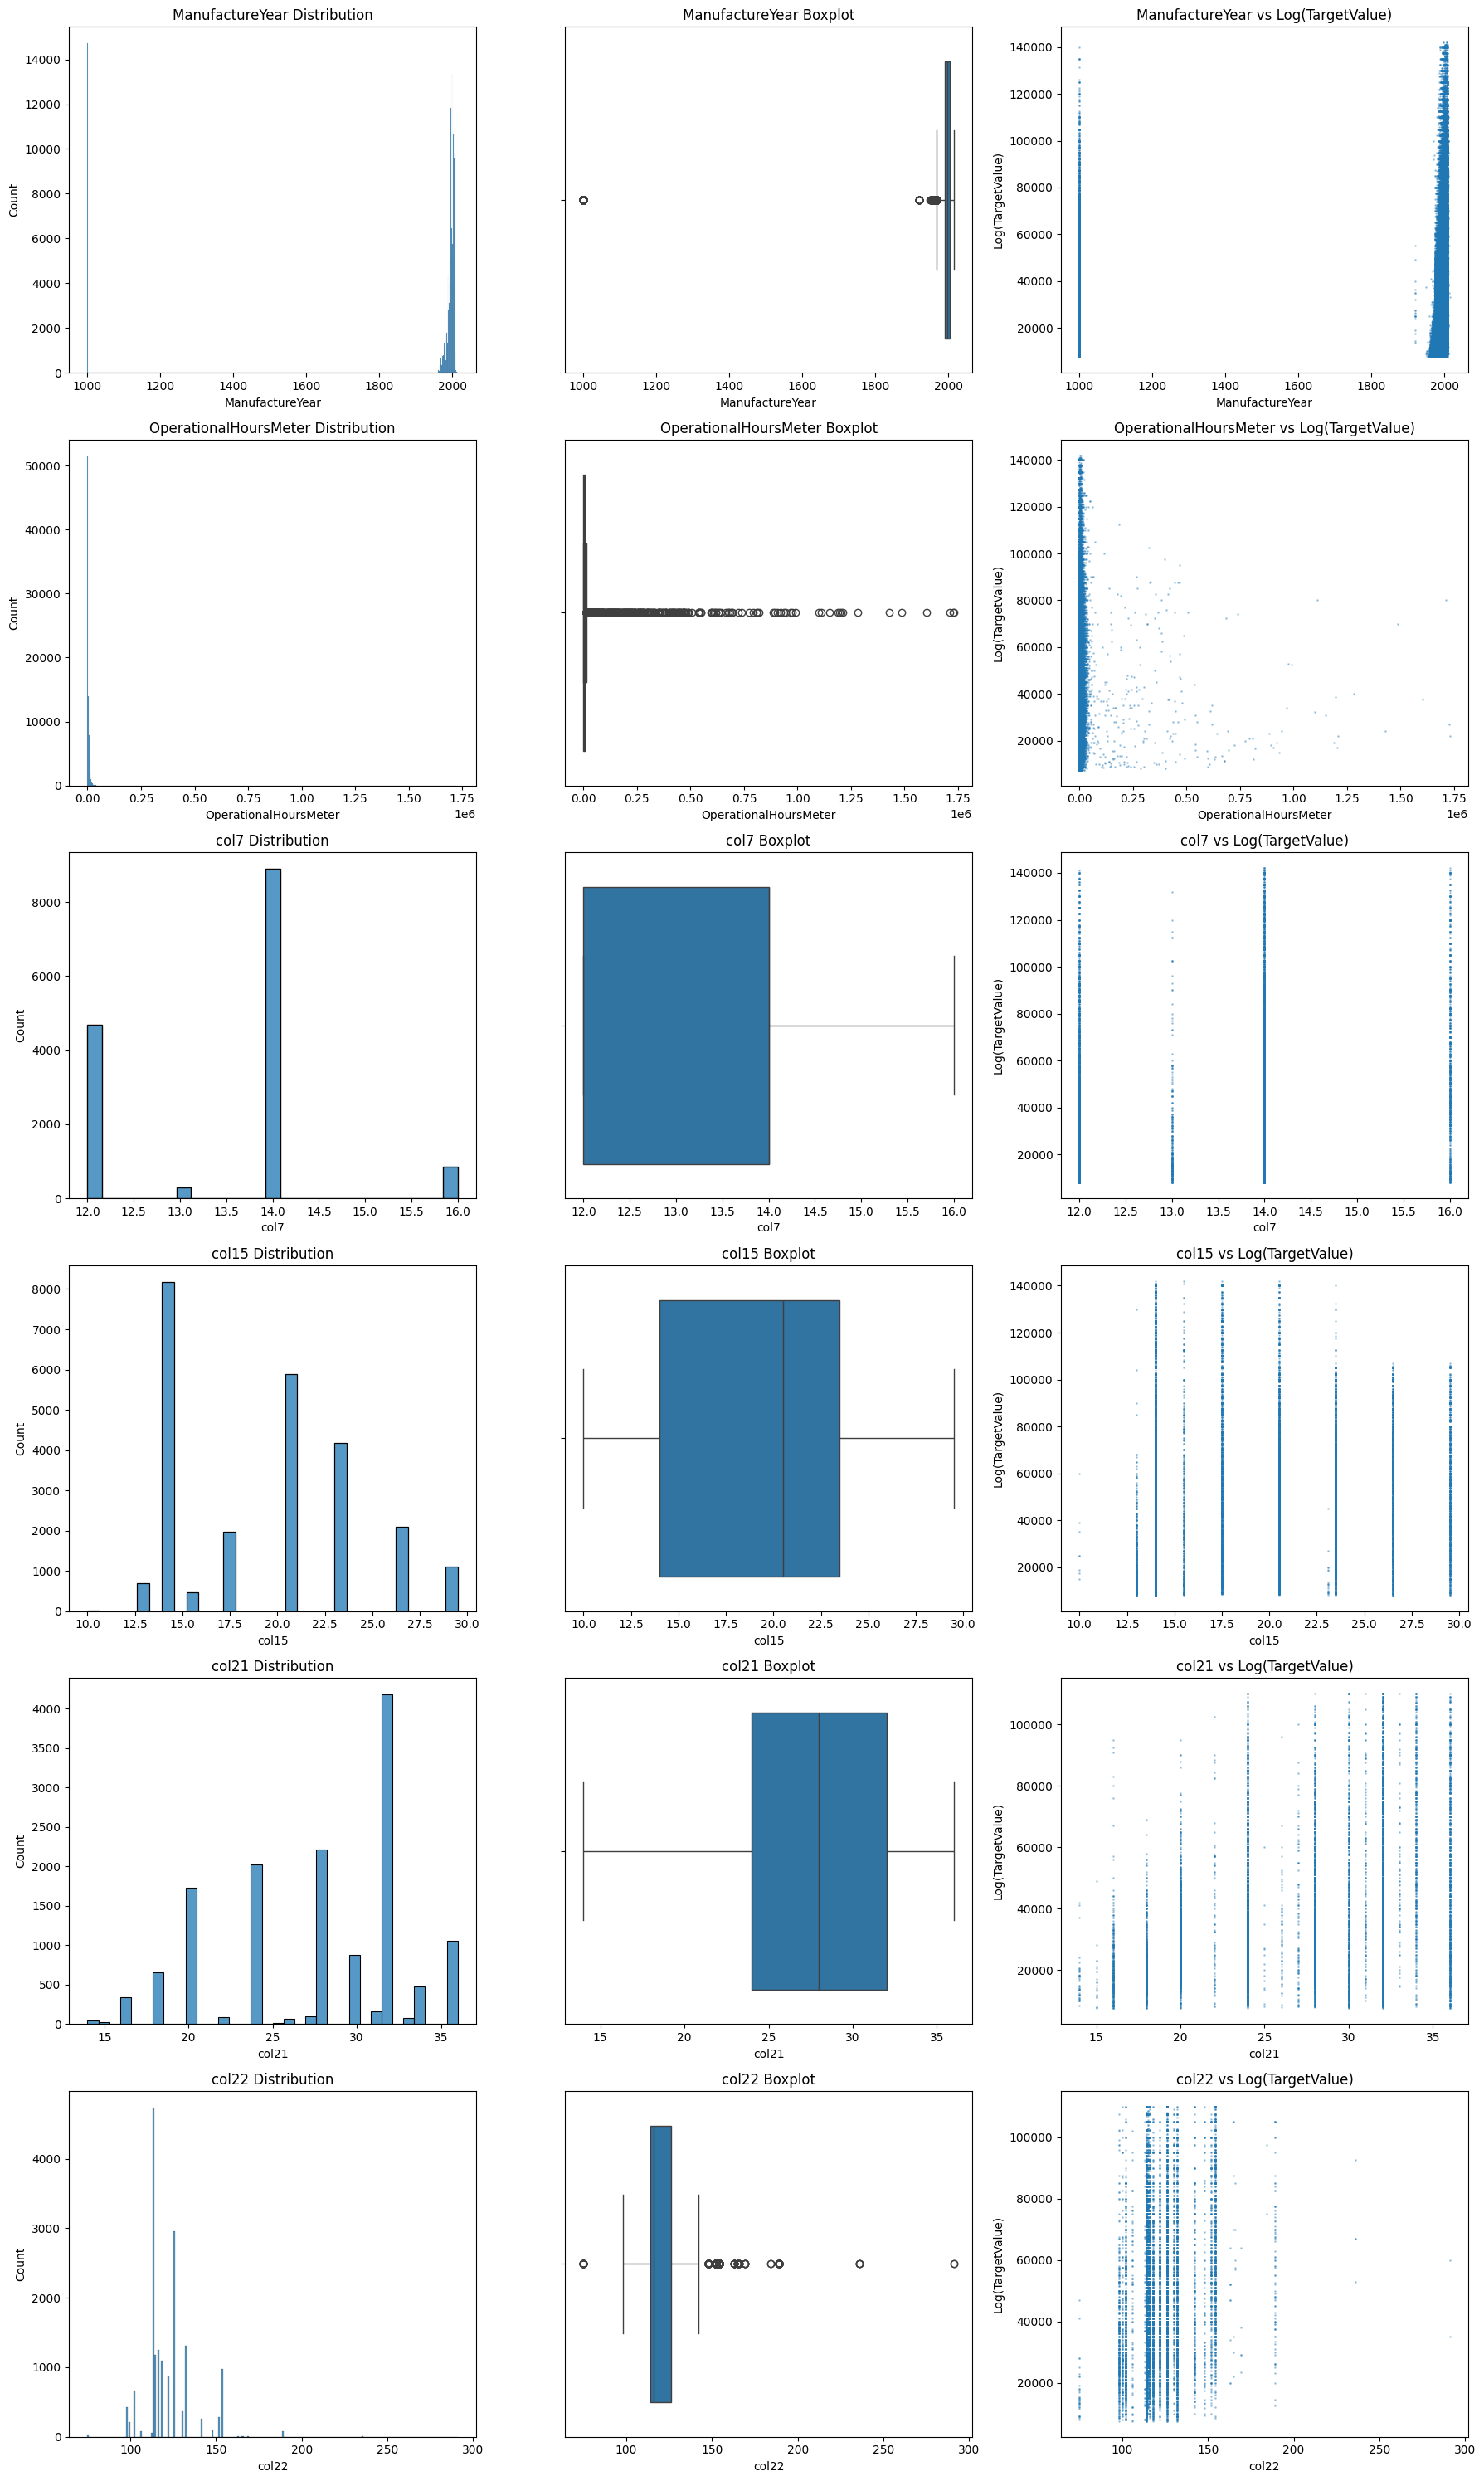

In [31]:
fig, axes = plt.subplots(len(numeric_cols), 3, figsize=(18, 5 * len(numeric_cols)))

for i, col in enumerate(numeric_cols):
    # 1. Distribution — shape of data
    sns.histplot(train_df[col].dropna(), ax=axes[i][0])
    axes[i][0].set_title(f'{col} Distribution')
    
    # 2. Boxplot — spot outliers
    sns.boxplot(x=train_df[col].dropna(), ax=axes[i][1])
    axes[i][1].set_title(f'{col} Boxplot')
    
    # 3. Scatter vs target — relationship with price
    axes[i][2].scatter(train_df[col], train_df['TargetValue'], alpha=0.3, s=1)
    axes[i][2].set_xlabel(col)
    axes[i][2].set_ylabel('Log(TargetValue)')
    axes[i][2].set_title(f'{col} vs Log(TargetValue)')

plt.tight_layout()
plt.show()

### Important observations:

#### ManufactureYear:

- 1001 is the min value of ManufactureYear, which is likely a placeholder for null, and should be removed
- Points around 1920 are outliers. But those may just be very old machines, and may add value to the target value

In [32]:
(train_df['ManufactureYear'] == 1001).sum()

np.int64(14719)

In [33]:
train_df.groupby('InventoryGroupCategory')['ManufactureYear'].apply(lambda x: (x==1001).mean()*100).sort_values(ascending=False).head(10)

InventoryGroupCategory
WL     12.091988
MG     11.373638
TEX    11.256301
TTT     8.382913
BL      5.076582
SSL     0.000000
Name: ManufactureYear, dtype: float64

#### OperationalHoursMeter

- This feature is highly right-skewed, with many values around zero. This need not be handled as new machines do have 0 operational hours

#### col7, col15, col21, col22:

- These are the features which had the feet and inches symbol
- These features have distinct values, making them seem categorical
- However, judging from the metadata provided, they are measurements of the machine
- Hence, we decide to keep them as numeric columns

## Categorical feature analysis - Univariate and Bivariate

In [34]:
cat_cols = train_df.select_dtypes(include=['object', 'category']).drop(columns = cols_to_drop).columns
for i in cat_cols:
    print(i)
print("Total: ", len(cat_cols))

TransactionID
AssetID
ProductConfigID
DataOriginCode
VendorPartnerID
UtilizationTier
Spec_FullDescriptor
Spec_BaseClass
Spec_SubClass
Spec_ReleaseSeries
Spec_VariantModifier
AssetScaleFactor
FunctionalClassification
RegionCode
InventoryGroupCategory
InventoryGroupDescription
col1
CabinType
col3
col4
DrivetrainType
col9
col10
col11
col12
col13
col14
col16
col19
col20
col25
col27
col28
col29
col30
Total:  35


### Fix potential capitalization inconsistencies

In DriveTrainType column, there was both "AutoShift" and "Autoshift". Hence for safety we convert all values to title case

In [35]:
obj_cols = train_df.select_dtypes(include='object').columns

for col in obj_cols:
    train_df[col] = train_df[col].str.strip().str.title()
    test_df[col] = test_df[col].str.strip().str.title()

### Number of unique values in each column

In [36]:
for col in cat_cols:
    print(f"{col}: {train_df[col].nunique()} unique")

TransactionID: 138701 unique
AssetID: 120111 unique
ProductConfigID: 3594 unique
DataOriginCode: 6 unique
VendorPartnerID: 31 unique
UtilizationTier: 3 unique
Spec_FullDescriptor: 3505 unique
Spec_BaseClass: 1249 unique
Spec_SubClass: 144 unique
Spec_ReleaseSeries: 113 unique
Spec_VariantModifier: 128 unique
AssetScaleFactor: 6 unique
FunctionalClassification: 65 unique
RegionCode: 52 unique
InventoryGroupCategory: 6 unique
InventoryGroupDescription: 6 unique
col1: 4 unique
CabinType: 3 unique
col3: 2 unique
col4: 2 unique
DrivetrainType: 6 unique
col9: 2 unique
col10: 11 unique
col11: 1 unique
col12: 3 unique
col13: 1 unique
col14: 2 unique
col16: 2 unique
col19: 2 unique
col20: 2 unique
col25: 3 unique
col27: 8 unique
col28: 4 unique
col29: 3 unique
col30: 2 unique


Here, we see that there are many high cardinality columns, while there are also columns that have just one unique value

### Analyse columns with 1 unique value

In [37]:
for col in cat_cols:
    if train_df[col].nunique() == 1:
        print(train_df.groupby('InventoryGroupCategory')[col].value_counts(dropna = False))

InventoryGroupCategory  col11
Bl                      NaN      10381
Mg                      NaN      18034
                        Yes       5371
Ssl                     NaN         66
Tex                     NaN      71018
Ttt                     NaN      14959
Wl                      NaN      18872
Name: count, dtype: int64
InventoryGroupCategory  col13
Bl                      NaN      10381
Mg                      NaN      11743
                        Yes      11662
Ssl                     NaN         66
Tex                     NaN      71018
Ttt                     NaN      14959
Wl                      NaN      18872
Name: count, dtype: int64


We can see that these 2 columns have value only for Mg. It is a mix of Yes and NaN

### col11, col13 — kept despite nunique() == 1

`nunique()` ignores NaN, so these look constant, but they are actually a 2-state
column: 'Yes' vs. missing.

'Yes' only occurs for Mg (Motor Graders) — everywhere else is 100% NaN. This matches the descriptions:
- col11 = load-bearing/shock-absorption interface → likely optional ride-control,
  grader-specific
- col13 = surface-finishing accessories → likely a grading/finishing attachment,
  core to a grader's job

Within Mg, presence still varies, hence we can keep them as NaN.

### Categorical columns are split into two groups based on cardinality

- **Low cardinality (≤20 unique values)**: Plotted with value counts and target distribution. 
  Few enough categories to be visually interpretable and extract meaningful insights.

- **High cardinality (>20 unique values)**: Only value counts printed. Too many categories 
  to plot meaningfully

In [38]:
low_cardinality = []
high_cardinality = []

for col in cat_cols:
    if train_df[col].nunique() < 20:
        low_cardinality.append(col)
    else:
        high_cardinality.append(col)

print("Low cardinality columns: ")
for i in low_cardinality:
    print(i)
print()
print("High cardinality columns: ")
for i in high_cardinality:
    print(i)

Low cardinality columns: 
DataOriginCode
UtilizationTier
AssetScaleFactor
InventoryGroupCategory
InventoryGroupDescription
col1
CabinType
col3
col4
DrivetrainType
col9
col10
col11
col12
col13
col14
col16
col19
col20
col25
col27
col28
col29
col30

High cardinality columns: 
TransactionID
AssetID
ProductConfigID
VendorPartnerID
Spec_FullDescriptor
Spec_BaseClass
Spec_SubClass
Spec_ReleaseSeries
Spec_VariantModifier
FunctionalClassification
RegionCode


### Low cardinality columns:



In [39]:
fig, axes = plt.subplots(len(low_cardinality), 2, figsize=(16, 6 * len(low_cardinality)))

for i, col in enumerate(low_cardinality):

    order = train_df[col].value_counts().index
    sns.countplot(data=train_df, x=col, order=order, ax=axes[i][0])
    axes[i][0].set_title(f'{col} Value Counts')
    axes[i][0].tick_params(axis='x', rotation=45)
    
    order2 = train_df.groupby(col)['TargetValue'].median().sort_values(ascending=False).index
    sns.boxplot(data=train_df, x=col, y='TargetValue', order=order2, ax=axes[i][1])
    axes[i][1].set_title(f'{col} vs Log(TargetValue)')
    axes[i][1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()


### Observations and decisions

- InventoryGroupDescription is just the full form of InventoryGroupCategory. Hence redundant and can be dropped
- DataOriginCode and col29 show minimal variance in target variable. Keep both for now and check performance
- col10 has rare categories. But they show considerable variance in target, so keep as is

### High cardinality columns

In [40]:
for col in high_cardinality:
    print(f"\n{col} ({train_df[col].nunique()} unique)")
    print(train_df[col].value_counts().head(10))
    print(f"Rare categories (<50 rows): {(train_df[col].value_counts() < 50).sum()}")


TransactionID (138701 unique)
TransactionID
1139309    1
1139316    1
1139317    1
1139322    1
1139333    1
1139336    1
1139339    1
1139344    1
1139345    1
1139351    1
Name: count, dtype: int64
Rare categories (<50 rows): 138701

AssetID (120111 unique)
AssetID
2283600    46
1896862    36
2285838    35
1746400    30
1942732    29
2268808    28
2282555    26
2271042    26
2296909    23
2300378    23
Name: count, dtype: int64
Rare categories (<50 rows): 120111

ProductConfigID (3594 unique)
ProductConfigID
3373     3751
3368     2948
1180     1556
23942    1509
4616     1280
4211     1273
3367     1260
88       1253
1188     1240
3361     1162
Name: count, dtype: int64
Rare categories (<50 rows): 3046

VendorPartnerID (31 unique)
VendorPartnerID
Ujf               67828
Gtx               18231
Mpf               15187
Unknown_Vendor     6549
Hcl                5753
Mnt                3786
Slt                2667
Dlc                2570
Mnj                2466
Snd                2461

### Observations and decision:

**AssetID**: We see that the same assetID does appear more than once sometimes, so out decision to useGroupKFold remains valid  

**ProductConfigID** : High cardinality ID-like column. Group rare categories (<50 rows) into 'Other' in Feature Engineering.

**VendorPartnerID** : UJF dominates

**Spec_BaseClass** :Majority of categories are rare. Only ~300 categories have sufficient representation. Group rare categories (<50 rows) into 'Other' in Feature Engineering.

**Spec_SubClass** : Single/double letter codes. Group rare categories (<50 rows) into 'Other' in Feature Engineering.

**Spec_ReleaseSeries** : Group rare categories (<50 rows) into 'Other' in Feature Engineering.

**Spec_VariantModifier** :
Mix of letter and numeric variant codes. Majority are rare.
Decision: Keep. Group rare categories (<50 rows) into 'Other' in Feature Engineering.

**FunctionalClassification** :
Descriptive size/capacity strings. Only 12 rare categories. No grouping needed.

**RegionCode** :
US states. Florida, Texas, California dominate. Only 3 rare categories.
Decision: Keep as-is. No action needed.

#### Columns to group rare categories: 

- ProductconfigID
- Spec_BaseClass
- Spec_SubClass
- Spec_ReleaseSeries
- Spec_VariantModifier

### Other observations:

- Spec_FullDescriptor is a concatenation of all other spec features, hence redundant and can be dropped
- In FunctionalClassification, the first part is just the InventoryGroupDescription. Hence we can trim that and keep only the measurement part

## Correlation heatmap

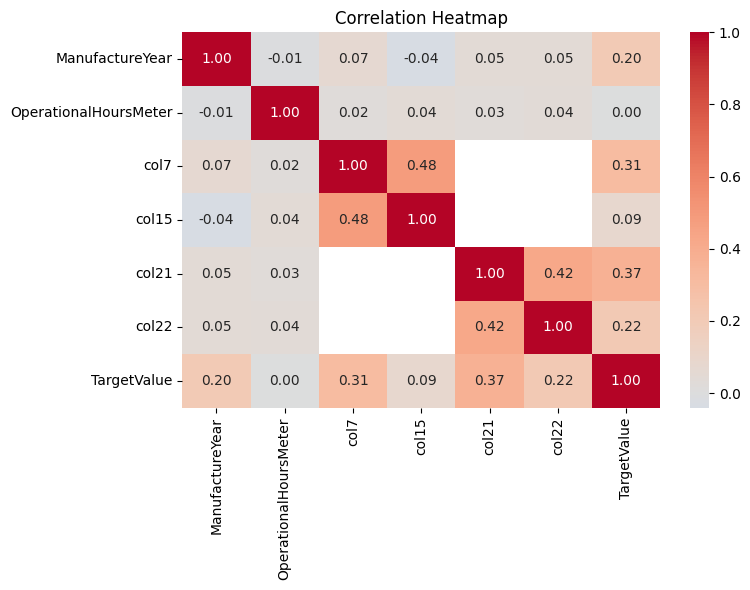

In [41]:
plt.figure(figsize=(8, 6))
numeric_cols = train_df.select_dtypes(include='number').columns.tolist()
numeric_cols = [col for col in numeric_cols if col != 'TargetValue']

corr = train_df[numeric_cols + ['TargetValue']].corr()

sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

### Observations

- None of the correlations are above 0.5, suggesting that the relationships may be non-linear
- OperationalHoursMeter has only 0.03 correlation with target. But may be due to non-linearity
- Similar case of col15
- No severe multicollinearity. (All below 0.5)

## Encoding and scaling

### Scaling:

Tree based models like LightGBM/XGBoost/CatBoost split data by asking feature ≤ threshold at each node. These splits depend only on the relative ordering of values within a feature, not their absolute scale or distribution. Hence, scaling is not applied

### Encoding:

This model uses tree model's native categorical support, which handles categorical features internally via optimal split-finding on category subsets rather than treating them as ordered numeric values. Passing raw categorical columns directly lets the model make more informative splits

# Data cleaning

- Drop unnecessary columns
- Replace invalid ManufactureYear
- Keep only the measurement part of FunctionalClassification

### Columns Dropped

* **ID Columns**
  * TransactionID
  * AssetID

* **Redundant Columns**
  * Spec_FullDescriptor
  * InventoryGroupDescription

* **High Null Columns**
  * Forks
  * col5
  * col6
  * col8
  * col18
  * col23
  * col24

* **Low Feature Importance**
  * InventoryGroupCategory
  * DriveTrainType
  * col28


In [42]:
class DataCleaner(BaseEstimator, TransformerMixin):

    def __init__(self, cols_to_drop, cap_hours=False):
        self.cols_to_drop = cols_to_drop
        self.cap_hours = cap_hours

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        df = X.copy()
        #Id columns and redundant columns
        df = df.drop(columns=['TransactionID', 'AssetID',
                               'Spec_FullDescriptor', 'InventoryGroupDescription'])
        #High null columns
        df = df.drop(columns=self.cols_to_drop)

        #Based on feature importance
        df = df.drop(columns=['InventoryGroupCategory', 'DrivetrainType', 'col28'])

        df['ManufactureYear'] = df['ManufactureYear'].replace(1001, np.nan)
        if self.cap_hours:
            df['OperationalHoursMeter'] = df['OperationalHoursMeter'].clip(upper=100_000)

        df['FunctionalClassification'] = df['FunctionalClassification'].astype('object')
        df['FunctionalClassification'] = df['FunctionalClassification'].str.split(' - ').str[1]
        return df

# Imputation

Impute RegionCode with mode

In [43]:
region_imputer = ColumnTransformer(
    transformers=[('region_impute', SimpleImputer(strategy='most_frequent'), ['RegionCode'])],
    remainder='passthrough',
    verbose_feature_names_out=False
).set_output(transform="pandas")

# Rare category grouping

In [44]:
class Encoder(BaseEstimator, TransformerMixin):
    def __init__(self, rare_cols, rare_threshold=50):
        self.rare_cols = rare_cols
        self.rare_threshold = rare_threshold

    def fit(self, X, y=None):
        self.rare_maps_ = {}
        for col in self.rare_cols:
            freq = X[col].astype(str).value_counts()
            self.rare_maps_[col] = freq[freq < self.rare_threshold].index
        return self

    def transform(self, X):
        df = X.copy()

        # rare-category grouping
        for col in self.rare_cols:
            df[col] = df[col].astype(str)
            df[col] = df[col].where(~df[col].isin(self.rare_maps_[col]), 'Other')

        return df

# Feature Engineering

Features created:

- HasValidManufactureYear (Whether it had a valid one or NaN(or 1001))
- TransactionYear (From TrandactionDate)
- TransactionQuarter (From TransactionQuarter)
- AssetAge (TransactionYear - ManufactureYear)
- HoursPerYear (OperationalHoursMeter/AssetAge)

In [45]:
class FeatureEngineer(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        df = X.copy()
        df['HasValidManufactureYear'] = df['ManufactureYear'].notna().astype(int)
        df['TransactionYear'] = df['TransactionDate'].dt.year
        df['TransactionQuarter'] = df['TransactionDate'].dt.quarter
        df = df.drop(columns=['TransactionDate'])
        df['AssetAge'] = df['TransactionYear'] - df['ManufactureYear']
        df['HoursPerYear'] = df['OperationalHoursMeter'] / df['AssetAge']
        return df.replace([np.inf, -np.inf], np.nan)

# Covert object type to category type

Learns the categorical vocabulary from train only, locks val/test to that same fixed vocabulary, and routes any unseen category to an 'Other' bucket

In [46]:
class CategoricalTypeFixer(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        self.cat_cols_ = X.select_dtypes(include=['object', 'category']).columns.tolist()
        self.categories_ = {}
        for col in self.cat_cols_:
            cats = X[col].astype(str).unique().tolist()
            if 'Other' not in cats:
                cats.append('Other')
            self.categories_[col] = cats
        return self

    def transform(self, X):
        df = X.copy()
        for col in self.cat_cols_:
            df[col] = df[col].astype(str)
            df[col] = df[col].where(df[col].isin(self.categories_[col]), 'Other')
            df[col] = pd.Categorical(df[col], categories=self.categories_[col])
        return df

# Pipeline

In [47]:
rare_cols = ['Spec_BaseClass', 'Spec_SubClass', 'Spec_ReleaseSeries',
             'Spec_VariantModifier', 'ProductConfigID']

preprocessor = Pipeline([
    ('clean', DataCleaner(cols_to_drop=cols_to_drop, cap_hours=False)),
    ('region_impute', region_imputer),
    ('encoder', Encoder(rare_cols=rare_cols)),
    ('engineer', FeatureEngineer()),
    ('finalize', CategoricalTypeFixer()),
])

X_raw = train_df.drop(columns=[target])
X_sample = preprocessor.fit_transform(X_raw)
cat_cols = X_sample.select_dtypes(include=['object', 'category']).columns.tolist()
print("Categorical columns:", cat_cols)

Categorical columns: ['RegionCode', 'ProductConfigID', 'DataOriginCode', 'VendorPartnerID', 'UtilizationTier', 'Spec_BaseClass', 'Spec_SubClass', 'Spec_ReleaseSeries', 'Spec_VariantModifier', 'AssetScaleFactor', 'FunctionalClassification', 'col1', 'CabinType', 'col3', 'col4', 'col9', 'col10', 'col11', 'col12', 'col13', 'col14', 'col16', 'col19', 'col20', 'col25', 'col27', 'col29', 'col30']


# Submission helper

This function is called in order to generate submission.csv from any y_pred

In [48]:
def submit(preds):
    submission = pd.DataFrame({
    'TransactionID': sample_sub["TransactionID"],
    'TargetValue': preds
})

    submission.to_csv('/kaggle/working/submission.csv', index=False)

# K-fold initialization

Group K-fold with AssetID as group and 5 folds

In [49]:
X_raw = train_df.drop(columns=['TargetValue'])
y_raw = np.log1p(train_df['TargetValue'])
groups = X_raw['AssetID']
gkf = GroupKFold(n_splits=5)

# Baseline: Linear regression

Linear regression with only numeric columns, imputed with median

In [50]:
baseline_pipe = Pipeline([
    ('select_numeric', ColumnTransformer([
        ('num', SimpleImputer(strategy='median'), selector(dtype_include=['int64', 'float64']))
    ], remainder='drop')),
    ('model', LinearRegression())
])

In [51]:
oof_baseline = np.zeros(len(X_raw))
baseline_scores = []

for fold, (tr_idx, va_idx) in enumerate(gkf.split(X_raw, y_raw, groups=groups)):
    X_tr, X_va = X_raw.iloc[tr_idx], X_raw.iloc[va_idx]
    y_tr, y_va = y_raw.iloc[tr_idx], y_raw.iloc[va_idx]

    pipe_b = clone(baseline_pipe)
    pipe_b.fit(X_tr, y_tr)

    preds = pipe_b.predict(X_va)
    oof_baseline[va_idx] = preds

    fold_rmse = np.sqrt(mse(y_va, preds))
    baseline_scores.append(fold_rmse)

    print(f"Fold {fold+1}: RMSLE = {fold_rmse:.6f}")

overall_rmse = np.sqrt(mse(y_raw, oof_baseline))

print("\nBaseline Results")
print(f"Mean Fold RMSLE : {np.mean(baseline_scores):.6f}")
print(f"Std Fold RMSLE  : {np.std(baseline_scores):.6f}")
print(f"Overall OOF RMSLE: {overall_rmse:.6f}")

Fold 1: RMSLE = 0.646669
Fold 2: RMSLE = 0.643480
Fold 3: RMSLE = 0.643467
Fold 4: RMSLE = 0.645214
Fold 5: RMSLE = 0.644688

Baseline Results
Mean Fold RMSLE : 0.644704
Std Fold RMSLE  : 0.001196
Overall OOF RMSLE: 0.644705


In [52]:
baseline_pipe.fit(X_raw, y_raw)
baseline_preds = np.expm1(baseline_pipe.predict(test_df))
# submit(baseline_preds)

# 3 models with default parameters

- LightGBM
- XGBoost
- CatBoost

In [53]:
oof_lgb = np.zeros(len(X_raw))
oof_xgb = np.zeros(len(X_raw))
oof_cat = np.zeros(len(X_raw))
fold_scores = {'lgb': [], 'xgb': [], 'cat': []}

for fold, (tr_idx, va_idx) in enumerate(gkf.split(X_raw, y_raw, groups=groups)):
    X_tr, X_va = X_raw.iloc[tr_idx], X_raw.iloc[va_idx]
    y_tr, y_va = y_raw.iloc[tr_idx], y_raw.iloc[va_idx]

    pipe_lgb = Pipeline([('preprocess', clone(preprocessor)),
                          ('model', lgb.LGBMRegressor(random_state=42, verbose=-1))])
    pipe_xgb = Pipeline([('preprocess', clone(preprocessor)),
                          ('model', xgb.XGBRegressor(random_state=42, enable_categorical=True))])

    pipe_lgb.fit(X_tr, y_tr)
    oof_lgb[va_idx] = pipe_lgb.predict(X_va)

    pipe_xgb.fit(X_tr, y_tr)
    oof_xgb[va_idx] = pipe_xgb.predict(X_va)

    cat_preprocessor = clone(preprocessor)
    X_tr_cat = cat_preprocessor.fit_transform(X_tr)
    X_va_cat = cat_preprocessor.transform(X_va)
    cat_cols_f = X_tr_cat.select_dtypes(include=['object', 'category']).columns.tolist()

    m_cat = CatBoostRegressor(random_state=42, verbose=0, task_type='GPU')
    m_cat.fit(X_tr_cat, y_tr, cat_features=cat_cols_f)
    oof_cat[va_idx] = m_cat.predict(X_va_cat)

    for name, oof in [('lgb', oof_lgb), ('xgb', oof_xgb), ('cat', oof_cat)]:
        fold_scores[name].append(np.sqrt(mse(y_va, oof[va_idx])))

    print(f"Fold {fold}: LGB={fold_scores['lgb'][-1]:.4f} XGB={fold_scores['xgb'][-1]:.4f} CAT={fold_scores['cat'][-1]:.4f}")


for name, oof in [("LGB", oof_lgb), ("XGB", oof_xgb), ("CAT", oof_cat)]:
    overall = np.sqrt(mse(y_raw, oof))
    mean_fold = np.mean(fold_scores[name.lower()])
    std_fold = np.std(fold_scores[name.lower()])

    print(f"{name}")
    print(f"Mean Fold RMSLE : {mean_fold:.6f}")
    print(f"Std Fold RMSLE  : {std_fold:.6f}")
    print(f"Overall OOF RMSLE: {overall:.6f}\n")

Fold 0: LGB=0.2273 XGB=0.2199 CAT=0.2263
Fold 1: LGB=0.2287 XGB=0.2229 CAT=0.2291
Fold 2: LGB=0.2261 XGB=0.2207 CAT=0.2253
Fold 3: LGB=0.2262 XGB=0.2190 CAT=0.2252
Fold 4: LGB=0.2264 XGB=0.2196 CAT=0.2249
LGB
Mean Fold RMSLE : 0.226940
Std Fold RMSLE  : 0.000976
Overall OOF RMSLE: 0.226942

XGB
Mean Fold RMSLE : 0.220412
Std Fold RMSLE  : 0.001376
Overall OOF RMSLE: 0.220417

CAT
Mean Fold RMSLE : 0.226141
Std Fold RMSLE  : 0.001556
Overall OOF RMSLE: 0.226146



In [54]:
comparison = pd.DataFrame({
    'Model': ['LightGBM', 'XGBoost', 'CatBoost'],
    'OOF RMSLE': [np.sqrt(mse(y_raw, oof_lgb)), np.sqrt(mse(y_raw, oof_xgb)), np.sqrt(mse(y_raw, oof_cat))],
    'Fold Std': [np.std(fold_scores['lgb']), np.std(fold_scores['xgb']), np.std(fold_scores['cat'])],
})
print(comparison.sort_values('OOF RMSLE'))

      Model  OOF RMSLE  Fold Std
1   XGBoost   0.220417  0.001376
2  CatBoost   0.226146  0.001556
0  LightGBM   0.226942  0.000976


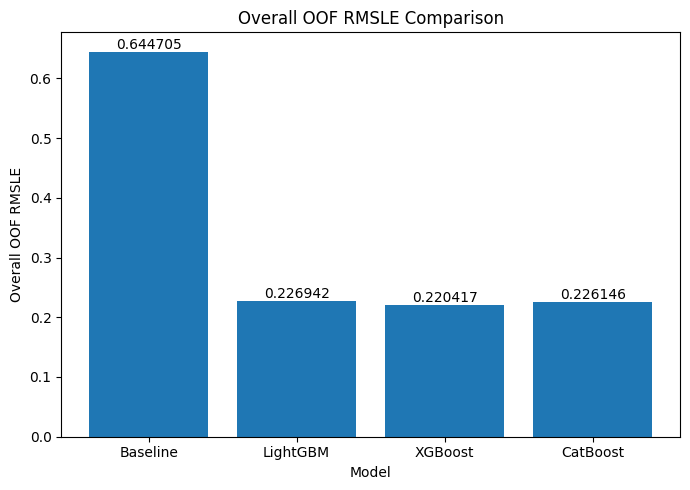

In [55]:
# Overall OOF RMSLE
baseline_oof = np.sqrt(mse(y_raw, oof_baseline))
lgb_oof = np.sqrt(mse(y_raw, oof_lgb))
xgb_oof = np.sqrt(mse(y_raw, oof_xgb))
cat_oof = np.sqrt(mse(y_raw, oof_cat))

models = ["Baseline", "LightGBM", "XGBoost", "CatBoost"]
scores = [baseline_oof, lgb_oof, xgb_oof, cat_oof]

import matplotlib.pyplot as plt

plt.figure(figsize=(7,5))
bars = plt.bar(models, scores)

plt.title("Overall OOF RMSLE Comparison")
plt.xlabel("Model")
plt.ylabel("Overall OOF RMSLE")

# Add values on top of bars
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height,
        f"{height:.6f}",
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.tight_layout()
plt.show()

# Hyperparameter Tuning

## LightGBM tuning

In [56]:
# param_dist_lgb = {
#     'model__max_depth': [4, 6, 8],
#     'model__learning_rate': [0.03, 0.05, 0.1],
#     'model__n_estimators': [500, 800, 1200],
#     'model__subsample': [0.7, 0.9, 1.0],
#     'model__colsample_bytree': [0.7, 0.9, 1.0],
# }

# pipe_lgb_search = Pipeline([
#     ('preprocess', clone(preprocessor)),
#     ('model', lgb.LGBMRegressor(random_state=42, verbose=-1))
# ])

# search_lgb = RandomizedSearchCV(
#     pipe_lgb_search,
#     param_distributions=param_dist_lgb,
#     n_iter=10,
#     cv=gkf,
#     scoring='neg_root_mean_squared_error',
#     random_state=42,
#     verbose=1
# )

# search_lgb.fit(X_raw, y_raw, groups=groups)   # <-- X_raw, not X

# best_params_lgb = search_lgb.best_params_
# print("LightGBM best params:", best_params_lgb)
# print("LightGBM best RMSE:", -search_lgb.best_score_)

### LightGBM Best parameters

- subsample = 1.0
- n_estimators = 1200
- max_depth = 6
- learning_rate = 0.1
- colsample_bytree = 0.9

## XGBoost tuning

In [57]:
# param_dist_xgb = {
#     'model__max_depth': [4, 6, 8],
#     'model__learning_rate': [0.03, 0.05, 0.1],
#     'model__n_estimators': [500, 800, 1200],
#     'model__subsample': [0.7, 0.9, 1.0],
#     'model__colsample_bytree': [0.7, 0.9, 1.0],
# }

# pipe_xgb_search = Pipeline([
#     ('preprocess', clone(preprocessor)),
#     ('model', xgb.XGBRegressor(random_state=42, enable_categorical=True, tree_method='hist'))
# ])

# search_xgb = RandomizedSearchCV(
#     pipe_xgb_search,
#     param_dist_xgb, n_iter=10, cv=gkf, scoring='neg_root_mean_squared_error',
#     random_state=42, verbose=1
# )
# search_xgb.fit(X_raw, y_raw, groups=groups)

# best_params_xgb = search_xgb.best_params_
# print("XGB best params:", best_params_xgb)
# print("XGB best RMSLE:", -search_xgb.best_score_)

### XGBoost best parameters

- subsample = 0.7
- n_estimators = 1200
- max_depth = 8
- learning_rate = 0.03
- colsample_bytree = 0.7

## CatBoost tuning

In [58]:
# X_sample = preprocessor.fit_transform(X_raw)
# cat_cols = X_sample.select_dtypes(include=['object', 'category']).columns.tolist()

# param_dist_cat = {
#     'depth': [4, 6, 8, 10],
#     'learning_rate': [0.02, 0.03, 0.05, 0.08, 0.1],
#     'iterations': [800, 1200, 1600],
#     'l2_leaf_reg': [1, 3, 5, 7],
# }

# search_cat = RandomizedSearchCV(
#     CatBoostRegressor(random_state=42, verbose=0, task_type='GPU'),
#     param_dist_cat, n_iter=15, cv=gkf, scoring='neg_root_mean_squared_error',
#     random_state=42, verbose=1
# )
# search_cat.fit(X_sample, y_raw, groups=groups, cat_features=cat_cols)

# best_params_cat = search_cat.best_params_
# print("CatBoost best params:", best_params_cat)
# print("CatBoost best RMSLE:", -search_cat.best_score_)

### CatBoost best parameters

- learning_rate = 0.08
- l2_leaf_reg = 5
- iterations = 1600
- depth = 10

# Validation on tuned models

In [59]:
oof_lgb_tuned = np.zeros(len(X_raw))
oof_xgb_tuned = np.zeros(len(X_raw))
oof_cat_tuned = np.zeros(len(X_raw))

fold_scores = {
    "lgb": [],
    "xgb": [],
    "cat": []
}

for fold, (tr_idx, va_idx) in enumerate(gkf.split(X_raw, y_raw, groups=groups), start=1):

    X_tr, X_va = X_raw.iloc[tr_idx], X_raw.iloc[va_idx]
    y_tr, y_va = y_raw.iloc[tr_idx], y_raw.iloc[va_idx]

    # LightGBM
    pipe_lgb_tuned = Pipeline([
        ('preprocess', clone(preprocessor)),
        ('model', lgb.LGBMRegressor(
            random_state=42,
            verbose=-1,
            subsample=1.0,
            n_estimators=1200,
            max_depth=6,
            learning_rate=0.1,
            colsample_bytree=0.9,
        ))
    ])

    pipe_lgb_tuned.fit(X_tr, y_tr)
    preds_lgb = pipe_lgb_tuned.predict(X_va)
    oof_lgb_tuned[va_idx] = preds_lgb
    fold_scores["lgb"].append(np.sqrt(mse(y_va, preds_lgb)))


    # XGBoost
    pipe_xgb_tuned = Pipeline([
        ('preprocess', clone(preprocessor)),
        ('model', xgb.XGBRegressor(
            random_state=42,
            enable_categorical=True,
            tree_method='hist',
            subsample=0.7,
            n_estimators=1200,
            max_depth=8,
            learning_rate=0.03,
            colsample_bytree=0.7,
        ))
    ])

    pipe_xgb_tuned.fit(X_tr, y_tr)
    preds_xgb = pipe_xgb_tuned.predict(X_va)
    oof_xgb_tuned[va_idx] = preds_xgb
    fold_scores["xgb"].append(np.sqrt(mse(y_va, preds_xgb)))


    # CatBoost
    cat_preprocessor = clone(preprocessor)

    X_tr_cat = cat_preprocessor.fit_transform(X_tr)
    X_va_cat = cat_preprocessor.transform(X_va)

    cat_cols_f = X_tr_cat.select_dtypes(
        include=["object", "category"]
    ).columns.tolist()

    m_cat = CatBoostRegressor(
        random_state=42,
        verbose=0,
        task_type="GPU",
        learning_rate=0.08,
        l2_leaf_reg=5,
        iterations=1600,
        depth=10,
    )

    m_cat.fit(
        X_tr_cat,
        y_tr,
        cat_features=cat_cols_f
    )

    preds_cat = m_cat.predict(X_va_cat)
    oof_cat_tuned[va_idx] = preds_cat
    fold_scores["cat"].append(np.sqrt(mse(y_va, preds_cat)))

    print(
        f"Fold {fold}: "
        f"LGB={fold_scores['lgb'][-1]:.6f} | "
        f"XGB={fold_scores['xgb'][-1]:.6f} | "
        f"CAT={fold_scores['cat'][-1]:.6f}"
    )


lgb_oof = np.sqrt(mse(y_raw, oof_lgb_tuned))
xgb_oof = np.sqrt(mse(y_raw, oof_xgb_tuned))
cat_oof = np.sqrt(mse(y_raw, oof_cat_tuned))

results = [
    ("LightGBM", "lgb", lgb_oof),
    ("XGBoost", "xgb", xgb_oof),
    ("CatBoost", "cat", cat_oof),
]

for model_name, key, overall in results:
    print(f"{model_name}")
    print(f"Mean Fold RMSLE   : {np.mean(fold_scores[key]):.6f}")
    print(f"Std Fold RMSLE    : {np.std(fold_scores[key]):.6f}")
    print(f"Overall OOF RMSLE : {overall:.6f}\n")

# Equal-Weight Ensemble
oof_ensemble_3 = (
    oof_lgb_tuned +
    oof_xgb_tuned +
    oof_cat_tuned
) / 3

ensemble_oof = np.sqrt(mse(y_raw, oof_ensemble_3))

print(f"3-Model Ensemble OOF RMSLE : {ensemble_oof:.6f}")

Fold 1: LGB=0.212209 | XGB=0.209491 | CAT=0.210801
Fold 2: LGB=0.215642 | XGB=0.212794 | CAT=0.213922
Fold 3: LGB=0.211202 | XGB=0.209530 | CAT=0.210241
Fold 4: LGB=0.210323 | XGB=0.209539 | CAT=0.210327
Fold 5: LGB=0.211472 | XGB=0.209375 | CAT=0.209841
LightGBM
Mean Fold RMSLE   : 0.212170
Std Fold RMSLE    : 0.001838
Overall OOF RMSLE : 0.212178

XGBoost
Mean Fold RMSLE   : 0.210146
Std Fold RMSLE    : 0.001326
Overall OOF RMSLE : 0.210150

CatBoost
Mean Fold RMSLE   : 0.211026
Std Fold RMSLE    : 0.001480
Overall OOF RMSLE : 0.211032

3-Model Ensemble OOF RMSLE : 0.206247


# Weighted ensemble

In [60]:
best_rmsle, best_weights = np.inf, None
for w_lgb in np.arange(0.1, 0.6, 0.1):
    for w_xgb in np.arange(0.1, 0.6, 0.1):
        w_cat = 1 - w_lgb - w_xgb
        if w_cat < 0.1 or w_cat > 0.6:
            continue
        blend = w_lgb * oof_lgb_tuned + w_xgb * oof_xgb_tuned + w_cat * oof_cat_tuned
        score = np.sqrt(mse(y_raw, blend))
        if score < best_rmsle:
            best_rmsle, best_weights = score, (w_lgb, w_xgb, w_cat)
print("Best weighted 3-model RMSLE:", best_rmsle, "\nweights:", best_weights)

Best weighted 3-model RMSLE: 0.206015786194039 
weights: (np.float64(0.2), np.float64(0.4), np.float64(0.4))


### Best weights:

LightGBM: 0.2  
XGBoost: 0.4  
CatBoost: 0.4

# Final submission

In [61]:
# Final LightGBM
final_pipe_lgb = Pipeline([
    ('preprocess', clone(preprocessor)),
    ('model', lgb.LGBMRegressor(
        random_state=42, verbose=-1, subsample=1.0, n_estimators=1200,
        max_depth=6, learning_rate=0.1, colsample_bytree=0.9,
    ))
])
final_pipe_lgb.fit(X_raw, y_raw)
pred_test_log_lgb = final_pipe_lgb.predict(test_df)

# Final XGBoost
final_pipe_xgb = Pipeline([
    ('preprocess', clone(preprocessor)),
    ('model', xgb.XGBRegressor(
        random_state=42, enable_categorical=True, tree_method='hist',
        subsample=0.7, n_estimators=1200, max_depth=8, learning_rate=0.03, colsample_bytree=0.7,
    ))
])
final_pipe_xgb.fit(X_raw, y_raw)
pred_test_log_xgb = final_pipe_xgb.predict(test_df)

# Final CatBoost
final_cat_preprocessor = clone(preprocessor)
X_full_cat = final_cat_preprocessor.fit_transform(X_raw)
test_cat = final_cat_preprocessor.transform(test_df)
cat_cols_final = X_full_cat.select_dtypes(include=['object', 'category']).columns.tolist()

final_cat_model = CatBoostRegressor(
    random_state=42, verbose=0, task_type='GPU',
    learning_rate=0.08, l2_leaf_reg=5, iterations=1600, depth=10,
)
final_cat_model.fit(X_full_cat, y_raw, cat_features=cat_cols_final)
pred_test_log_cat = final_cat_model.predict(test_cat)

# Weighted ensemble on log scale (weights from grid search: lgb=0.2, xgb=0.4, cat=0.4), then transform once
pred_test_ensemble_log = 0.2 * pred_test_log_lgb + 0.4 * pred_test_log_xgb + 0.4 * pred_test_log_cat
pred_test_ensemble = np.expm1(pred_test_ensemble_log)
submit(pred_test_ensemble)

# Feature importance

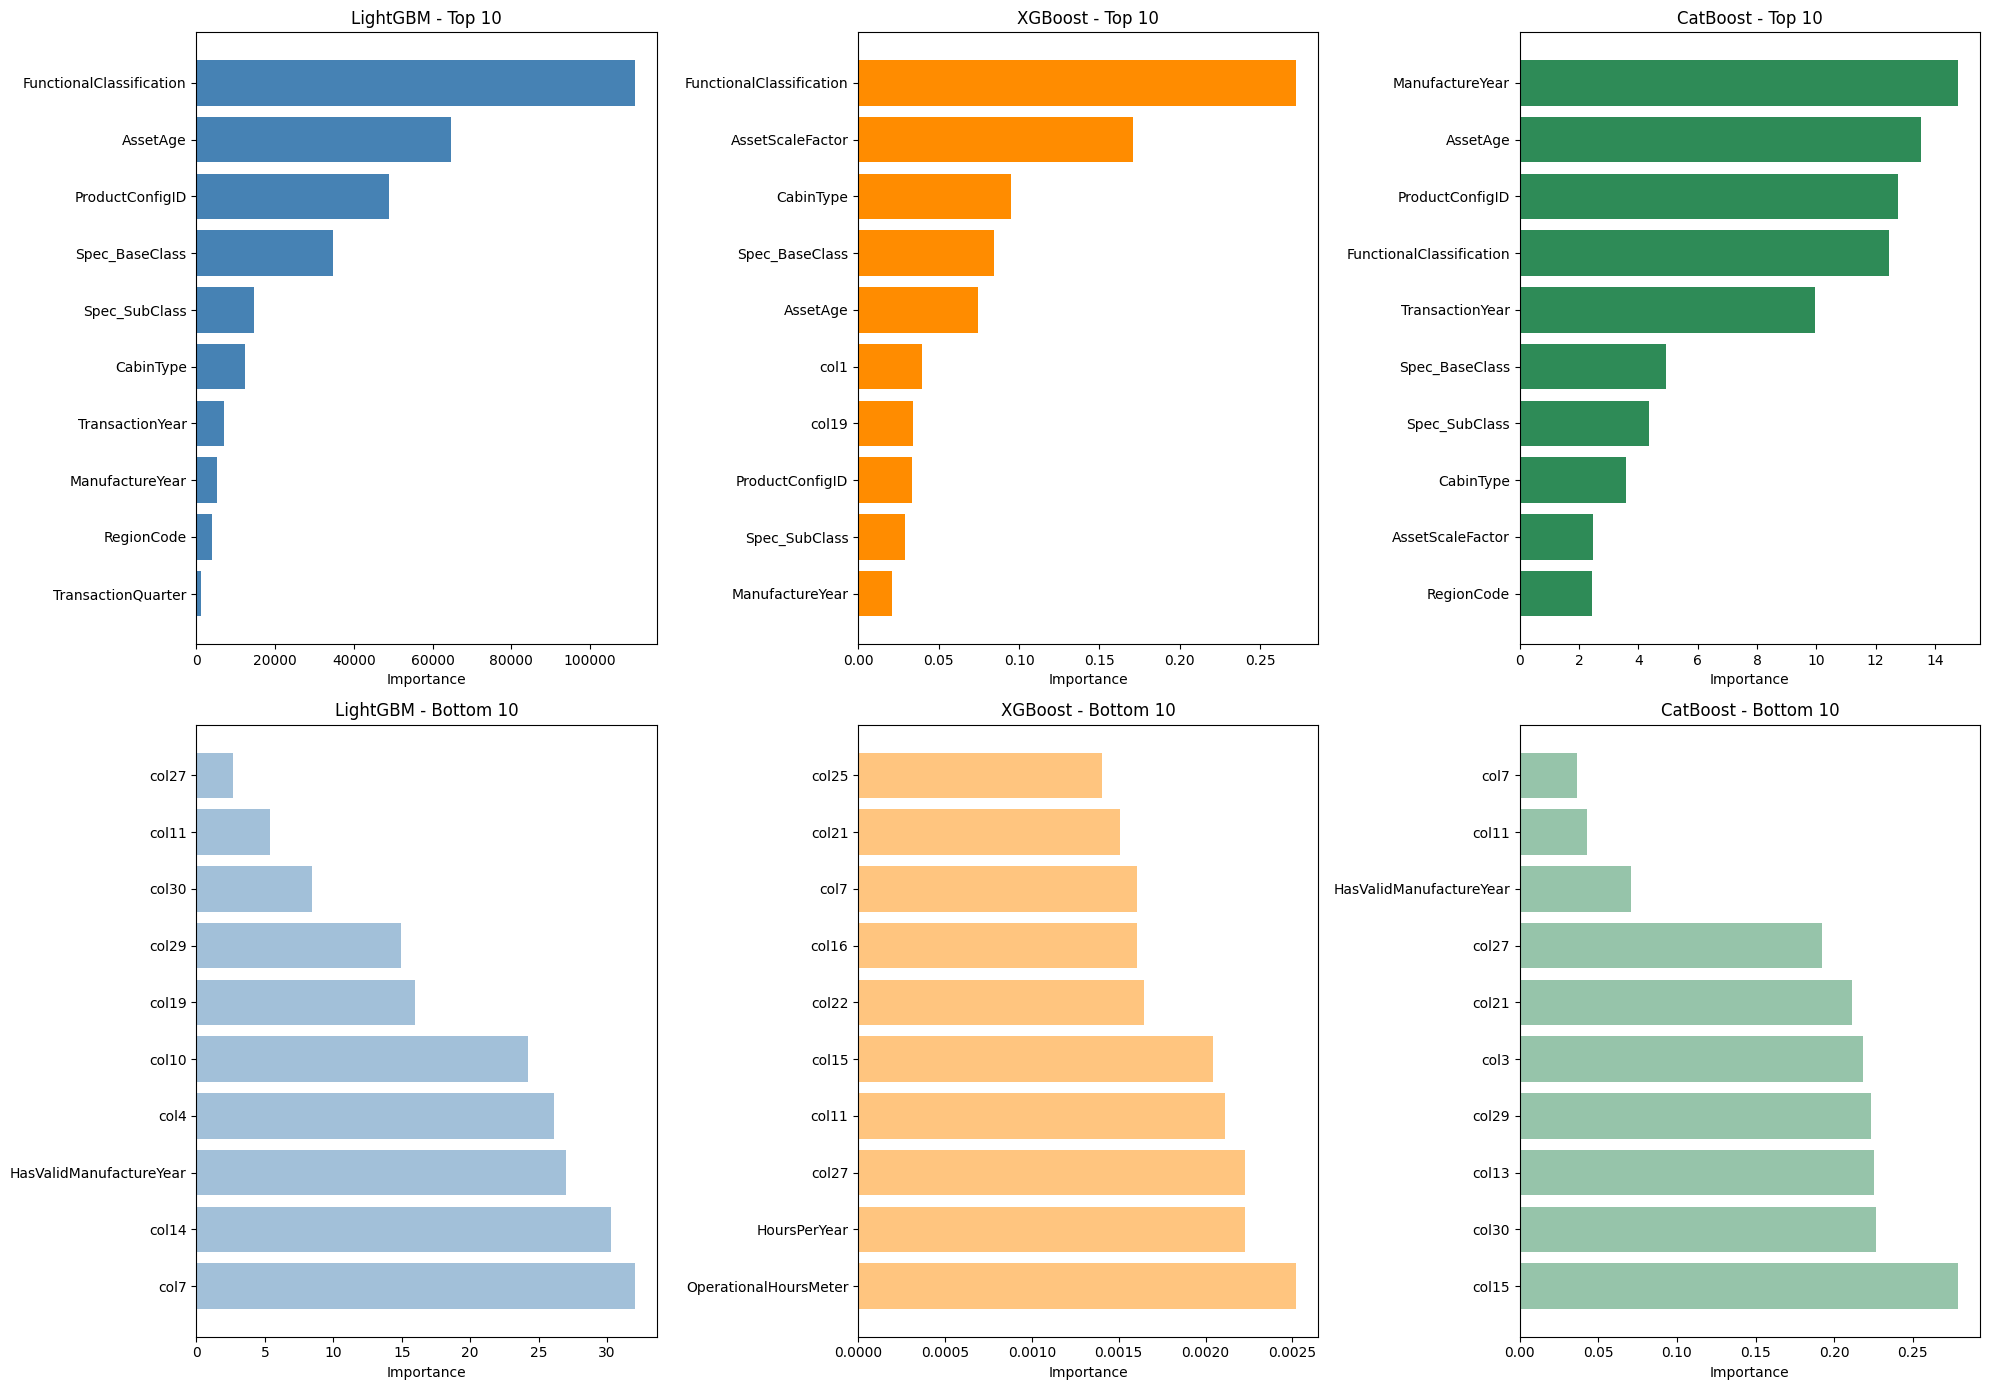


LightGBM - Top 10
                 Feature    Importance
FunctionalClassification 111365.972922
                AssetAge  64550.849028
         ProductConfigID  48882.968030
          Spec_BaseClass  34807.773634
           Spec_SubClass  14687.025370
               CabinType  12221.898666
         TransactionYear   7047.332892
         ManufactureYear   5334.958444
              RegionCode   3893.778298
      TransactionQuarter   1111.845996

LightGBM - Bottom 10
                Feature  Importance
                  col27    2.667206
                  col11    5.401673
                  col30    8.450186
                  col29   14.954658
                  col19   15.962018
                  col10   24.192247
                   col4   26.134714
HasValidManufactureYear   26.974982
                  col14   30.310887
                   col7   32.017755

XGBoost - Top 10
                 Feature  Importance
FunctionalClassification    0.272450
        AssetScaleFactor    0.170923
     

In [62]:
X_transformed = preprocessor.fit_transform(X_raw)
feature_names = X_transformed.columns.tolist()

lgb_model = final_pipe_lgb.named_steps['model']

imp_df_lgb = pd.DataFrame({
    'Feature': feature_names,
    'Importance': lgb_model.booster_.feature_importance(
        importance_type='gain'
    )
})

xgb_model = final_pipe_xgb.named_steps['model']

imp_df_xgb = pd.DataFrame({
    'Feature': feature_names,
    'Importance': xgb_model.feature_importances_
})


imp_df_cat = pd.DataFrame({
    'Feature': feature_names,
    'Importance': final_cat_model.get_feature_importance()
})

top_n = 10

models = [
    ('LightGBM', imp_df_lgb, 'steelblue'),
    ('XGBoost', imp_df_xgb, 'darkorange'),
    ('CatBoost', imp_df_cat, 'seagreen'),
]

fig, axes = plt.subplots(2, 3, figsize=(20, 14))

for col, (title, imp_df, color) in enumerate(models):

    top = (
        imp_df.sort_values("Importance", ascending=False)
              .head(top_n)
              .sort_values("Importance")
    )

    axes[0, col].barh(top["Feature"], top["Importance"], color=color)
    axes[0, col].set_title(f"{title} - Top {top_n}")
    axes[0, col].set_xlabel("Importance")

    bottom = (
        imp_df.sort_values("Importance")
              .head(top_n)
              .sort_values("Importance", ascending=False)
    )

    axes[1, col].barh(
        bottom["Feature"],
        bottom["Importance"],
        color=color,
        alpha=0.5
    )

    axes[1, col].set_title(f"{title} - Bottom {top_n}")
    axes[1, col].set_xlabel("Importance")

plt.tight_layout()
plt.show()

for title, imp_df in [
    ('LightGBM', imp_df_lgb),
    ('XGBoost', imp_df_xgb),
    ('CatBoost', imp_df_cat)
]:
    print(f"\n{title} - Top 10")
    print(imp_df.sort_values('Importance', ascending=False).head(10).to_string(index=False))

    print(f"\n{title} - Bottom 10")
    print(imp_df.sort_values('Importance').head(10).to_string(index=False))